# Плата за въезд в центр Манхэттена: эффект на поездки жёлтого такси

**Вопрос.** Как плата за въезд в Congestion Relief Zone (действует с 5 января 2025) повлияла на поездки жёлтого такси: число поездок, среднюю скорость и тариф по счётчику.

**Метод.** Естественный эксперимент. Районы внутри зоны — тест (`cbd`), районы Манхэттена вне зоны — контроль (`control`). Эффект оцениваем методом «разность разностей» (difference-in-differences, DiD) на дневных данных из витрин `mart.daily_group_metrics` и `mart.daily_diff`.

**План.**
1. Данные и графики по дням.
2. Эффект для трёх метрик: разность средних, критерий Уэлча, бутстреп-интервал.
3. Поправка Бонферрони на три сравнения.
4. Плацебо-тест на периоде до введения платы.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

sys.path.append(str(Path.cwd().parent / "src"))
from db import get_engine

FEE_DATE = pd.Timestamp("2025-01-05")       # первый день действия платы
HOLIDAY_START = pd.Timestamp("2024-12-20")  # праздники: исключаются из анализа
HOLIDAY_END = pd.Timestamp("2025-01-05")
PLACEBO_DATE = pd.Timestamp("2024-11-15")   # фиктивная дата для плацебо-теста

N_BOOT = 10_000  # число выборок бутстрепа
SEED = 42

# метрика в mart.daily_diff -> подпись
METRICS = {
    "log_trips_diff": "log(число поездок)",
    "speed_diff": "скорость, миль/ч",
    "fare_diff": "тариф по счётчику, $",
}
COLORS = {"cbd": "#2a78d6", "control": "#eb6834"}

## 1. Данные

`mart.daily_group_metrics` — одна строка на дату и группу: число поездок, средняя скорость (сумма миль / сумма часов) и средний тариф по счётчику (только поездки с `payment_type` 1–4, без Flex Fare). Учитываются только поездки, у которых и посадка, и высадка в районах одной группы.

`mart.daily_diff` — разности «cbd минус control» по каждой дате, для числа поездок разность логарифмов.

Колонка `period`: `before` — до 19 декабря 2024 включительно, `holiday` — с 20 декабря по 5 января (исключается), `after` — с 6 января 2025.

In [2]:
engine = get_engine()

daily = pd.read_sql(
    "SELECT * FROM mart.daily_group_metrics ORDER BY pickup_date, zone_group",
    engine, parse_dates=["pickup_date"],
)
diff = pd.read_sql(
    "SELECT * FROM mart.daily_diff ORDER BY pickup_date",
    engine, parse_dates=["pickup_date"],
)

print("daily:", daily.shape, " diff:", diff.shape)
daily.groupby(["period", "zone_group"]).size().unstack()

daily: (364, 7)  diff: (182, 6)


zone_group,cbd,control
period,,
after,85,85
before,80,80
holiday,17,17


In [3]:
daily.head()

,pickup_date,zone_group,period,trips,avg_speed_mph,avg_fare,avg_fare_all
0,2024-10-01,cbd,before,45176,7.687182,13.283290,13.417922
1,2024-10-01,control,before,8225,8.972008,9.992096,10.256188
2,2024-10-02,cbd,before,42083,7.403673,13.545413,13.650369
3,2024-10-02,control,before,8094,9.030544,9.998842,10.218903
4,2024-10-03,cbd,before,41581,8.232444,12.799615,12.862809


### Метрики по дням

Ось числа поездок логарифмическая: в `cbd` поездок в несколько раз больше, чем в `control`, и в линейном масштабе контроль сливается с осью.

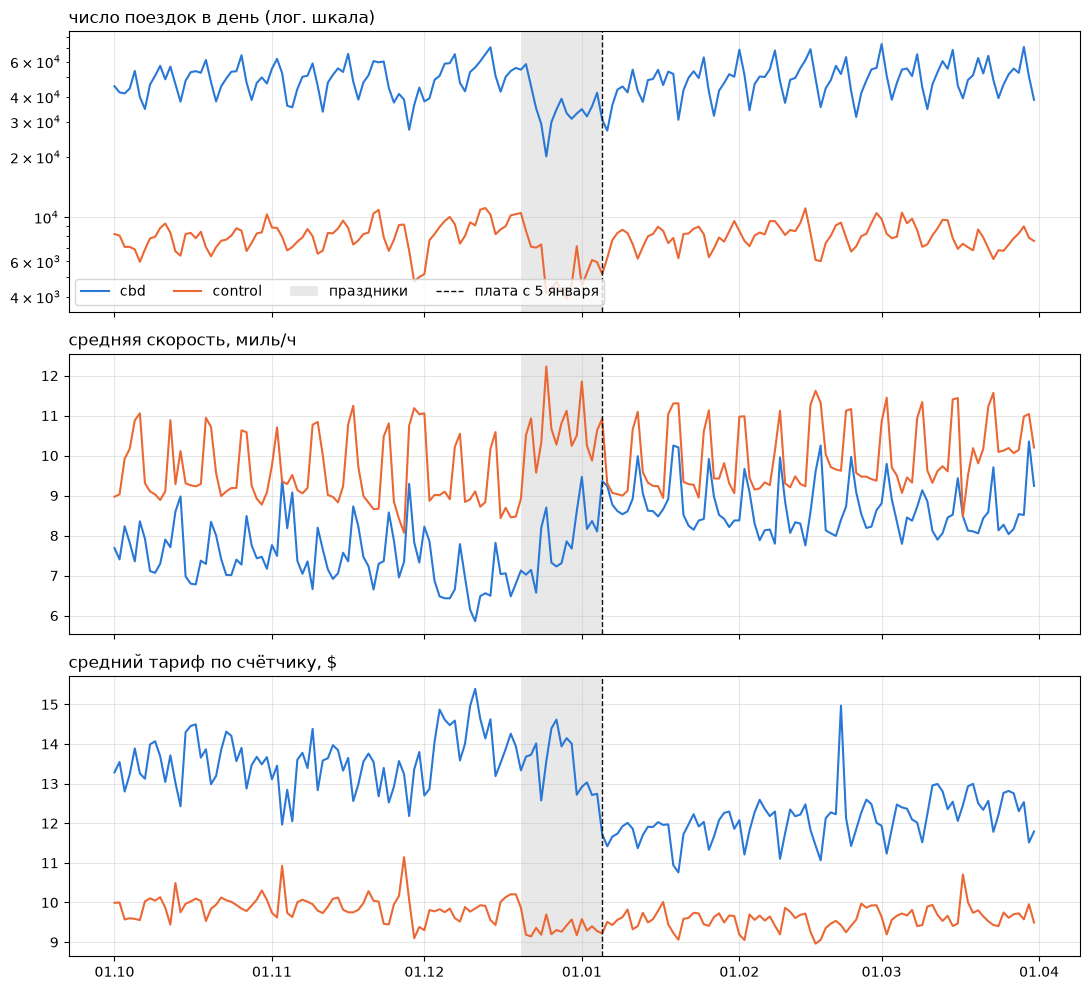

In [4]:
def mark_periods(ax):
    # Закрашенные праздники и линия в день введения платы.
    ax.axvspan(HOLIDAY_START, HOLIDAY_END, color="#d9d9d9", alpha=0.6, lw=0, label="праздники")
    ax.axvline(FEE_DATE, color="#0b0b0b", lw=1, ls="--", label="плата с 5 января")


GROUP_PLOTS = [
    ("trips", "число поездок в день (лог. шкала)"),
    ("avg_speed_mph", "средняя скорость, миль/ч"),
    ("avg_fare", "средний тариф по счётчику, $"),
]

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, (column, title) in zip(axes, GROUP_PLOTS):
    for group, part in daily.groupby("zone_group"):
        ax.plot(part["pickup_date"], part[column], lw=1.5, color=COLORS[group], label=group)
    mark_periods(ax)
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[0].legend(ncol=4, loc="lower left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout()

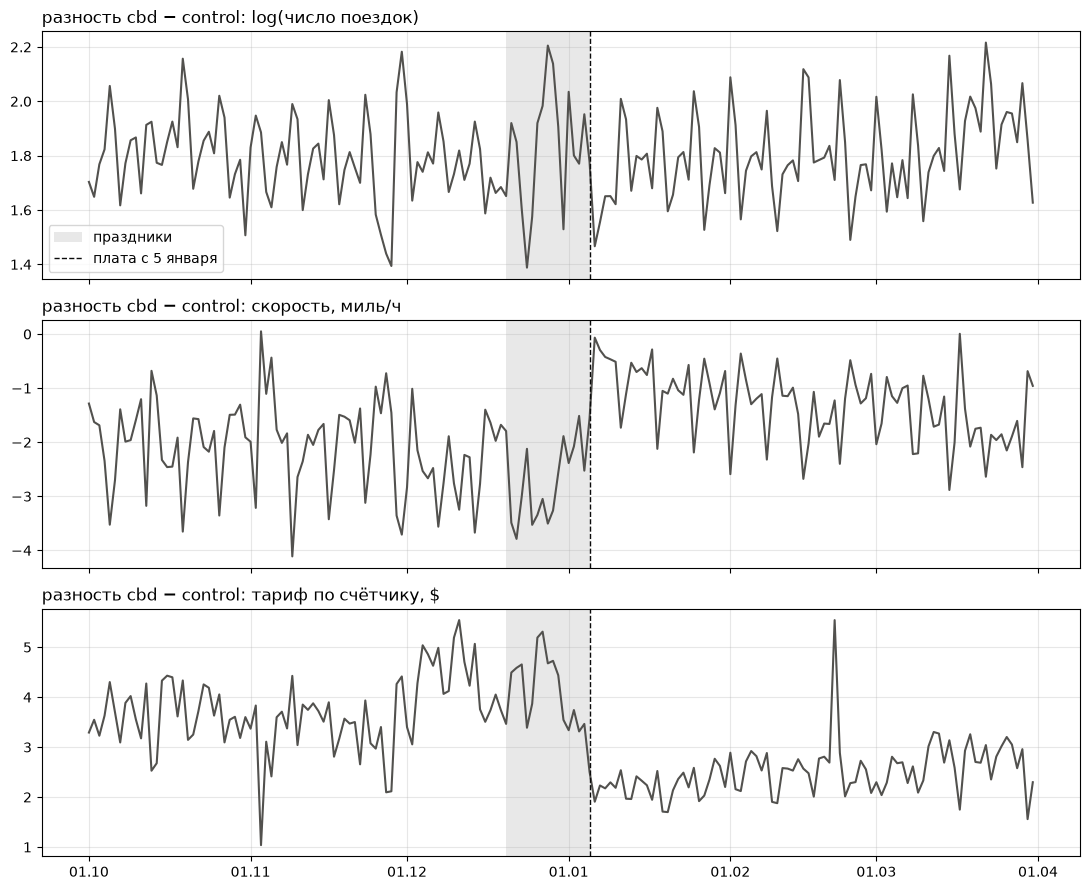

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (metric, label) in zip(axes, METRICS.items()):
    ax.plot(diff["pickup_date"], diff[metric], lw=1.5, color="#52514e")
    mark_periods(ax)
    ax.set_title(f"разность cbd − control: {label}", loc="left")
    ax.grid(alpha=0.3)
axes[0].legend(loc="lower left")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout()

## 2. Оценка эффекта

Для каждой даты $t$ считаем разность между группами:

$$d_t = Y_{\text{cbd},\,t} - Y_{\text{control},\,t},$$

где для числа поездок $Y = \ln(\text{trips})$, поэтому $d_t$ — разность в процентах, а не в штуках. Эффект платы — изменение средней разности после её введения:

$$\widehat{DiD} = \overline{d}_{\text{after}} - \overline{d}_{\text{before}}.$$

**Критерий Уэлча** сравнивает средние двух выборок дней, не предполагая равных дисперсий: $D(d_t)$ до и после платы может отличаться.

$$t = \frac{\overline{d}_{\text{after}} - \overline{d}_{\text{before}}}{\sqrt{\hat D_{\text{after}} / n_{\text{after}} + \hat D_{\text{before}} / n_{\text{before}}}}.$$

**Бутстреп-интервал.** $10\,000$ раз выбираем дни «до» и дни «после» с возвращением, каждый раз считаем разность средних. Интервал — перцентили 2.5% и 97.5% полученных разностей.

In [6]:
def welch_test(d_after, d_before):
    result = stats.ttest_ind(d_after, d_before, equal_var=False)
    return result.statistic, result.pvalue


def bootstrap_ci(d_after, d_before, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    d_after = d_after.to_numpy()
    d_before = d_before.to_numpy()
    effects = []
    for _ in range(n_boot):
        sample_after = rng.choice(d_after, size=len(d_after), replace=True)
        sample_before = rng.choice(d_before, size=len(d_before), replace=True)
        effects.append(sample_after.mean() - sample_before.mean())
    return np.percentile(effects, 2.5), np.percentile(effects, 97.5)


def estimate_effects(diff_part):
    # diff_part: строки mart.daily_diff с period in {before, after}
    rows = []
    for metric, label in METRICS.items():
        d_before = diff_part.loc[diff_part["period"] == "before", metric]
        d_after = diff_part.loc[diff_part["period"] == "after", metric]
        t, p = welch_test(d_after, d_before)
        ci_low, ci_high = bootstrap_ci(d_after, d_before)
        rows.append({
            "metric": label,
            "mean_before": d_before.mean(),
            "mean_after": d_after.mean(),
            "effect": d_after.mean() - d_before.mean(),
            "ci_low": ci_low,
            "ci_high": ci_high,
            "t_welch": t,
            "p_welch": p,
        })
    return pd.DataFrame(rows).set_index("metric")

In [7]:
diff_main = diff[diff["period"].isin(["before", "after"])]
print("дней before:", (diff_main["period"] == "before").sum(), " дней after:", (diff_main["period"] == "after").sum())

results = estimate_effects(diff_main)
results.round(4)

дней before: 80  дней after: 85


,mean_before,mean_after,effect,ci_low,ci_high,t_welch,p_welch
metric,,,,,,,
log(число поездок),1.7952,1.8040,0.0089,-0.0377,0.0563,0.3620,0.7178
"скорость, миль/ч",-2.0950,-1.3039,0.7911,0.5618,1.0195,6.7889,0.0000
"тариф по счётчику, $",3.6900,2.5064,-1.1836,-1.3773,-0.9851,-11.8023,0.0000


In [8]:
# Для числа поездок эффект в логарифмах; в процентах: exp(effect) - 1.
trips_effect = results.loc[METRICS["log_trips_diff"], "effect"]
print(f"число поездок: эффект {trips_effect:.4f} в логарифмах, это {np.exp(trips_effect) - 1:+.1%}")

число поездок: эффект 0.0089 в логарифмах, это +0.9%


## 3. Поправка Бонферрони

Проверяем три гипотезы, по одной на метрику. При уровне $\alpha = 0.05$ для каждой вероятность хотя бы одной ложной находки среди трёх выше 5%. Поправка Бонферрони: каждое p-value умножаем на число тестов $m = 3$ (но не больше 1) и сравниваем с обычным порогом 0.05.

In [9]:
def bonferroni(p_values, n_tests):
    return np.minimum(p_values * n_tests, 1)


results["p_bonferroni"] = bonferroni(results["p_welch"], len(METRICS))
results["significant"] = results["p_bonferroni"] < 0.05
results.round(4)

,mean_before,mean_after,effect,ci_low,ci_high,t_welch,p_welch,p_bonferroni,significant
metric,,,,,,,,,
log(число поездок),1.7952,1.8040,0.0089,-0.0377,0.0563,0.3620,0.7178,1.0,False
"скорость, миль/ч",-2.0950,-1.3039,0.7911,0.5618,1.0195,6.7889,0.0000,0.0,True
"тариф по счётчику, $",3.6900,2.5064,-1.1836,-1.3773,-0.9851,-11.8023,0.0000,0.0,True


**Вывод по эффекту.**

1. Скорость: до введения платы поездки внутри зоны были в среднем на 2,10 мили/ч медленнее, чем в контроле, после — на 1,30 мили/ч. Эффект +0,79 мили/ч, 95% бутстреп-интервал [0,56; 1,02], t = 6,79.
2. Тариф по счётчику: разность зона минус контроль снизилась с 3,69 до 2,51 $. Эффект −1,18 $, интервал [−1,38; −0,99], t = −11,80.
3. Число поездок: Эффект 0,0089 (в лог), то есть +0,9%. Интервал [−0,038; 0,056] содержит ноль, t = 0,36.
4. После поправки Бонферрони значимы эффекты на скорость и тариф (p < 0,0001), эффект на число поездок незначим (p = 1,0). Это согласуется с бутстрепом: интервалы для скорости и тарифа не содержат ноль, для числа поездок содержат.
5. Снижение тарифа по направлению согласуется с ростом скорости

## 4. Плацебо-тест

Берём только период `before` и делаем вид, что плату ввели 15 ноября 2024: `before` — до 14 ноября, `after` — с 15 ноября по 19 декабря. Плата в это время не действовала, поэтому честная процедура должна показать незначимый эффект. Если «эффект» всё же найдётся, значит, метод ловит что-то другое: тренд, сезонность или зависимость дней.

In [10]:
placebo = diff[diff["period"] == "before"].copy()
placebo["period"] = np.where(placebo["pickup_date"] < PLACEBO_DATE, "before", "after")
print("дней before:", (placebo["period"] == "before").sum(), " дней after:", (placebo["period"] == "after").sum())

results_placebo = estimate_effects(placebo)
results_placebo["p_bonferroni"] = bonferroni(results_placebo["p_welch"], len(METRICS))
results_placebo["significant"] = results_placebo["p_bonferroni"] < 0.05
results_placebo.round(4)

дней before: 45  дней after: 35


,mean_before,mean_after,effect,ci_low,ci_high,t_welch,p_welch,p_bonferroni,significant
metric,,,,,,,,,
log(число поездок),1.8156,1.7689,-0.0467,-0.1124,0.0220,-1.3373,0.1859,0.5577,False
"скорость, миль/ч",-1.9873,-2.2335,-0.2462,-0.6000,0.1139,-1.3340,0.1863,0.5590,False
"тариф по счётчику, $",3.5643,3.8516,0.2873,-0.0382,0.6163,1.6795,0.0982,0.2945,False


In [11]:
comparison = pd.DataFrame({
    "эффект (плата)": results["effect"],
    "p Бонферрони (плата)": results["p_bonferroni"],
    "эффект (плацебо)": results_placebo["effect"],
    "p Бонферрони (плацебо)": results_placebo["p_bonferroni"],
})
comparison.round(4)

,эффект (плата),p Бонферрони (плата),эффект (плацебо),p Бонферрони (плацебо)
metric,,,,
log(число поездок),0.0089,1.0,-0.0467,0.5577
"скорость, миль/ч",0.7911,0.0,-0.2462,0.5590
"тариф по счётчику, $",-1.1836,0.0,0.2873,0.2945


**Вывод по плацебо.**

1. При фиктивной дате 15 ноября ни один эффект не значим: p с поправкой Бонферрони 0,56, 0,56 и 0,29, все бутстреп-интервалы содержат ноль.
2. Плацебо-оценки меньше основных по модулю и противоположны по знаку: для скорости −0,25 против 0,79, для тарифа 0,29 против −1,18. Для числа поездок обе оценки незначимы.

## Выводы

1. После введения платы за въезд поездки жёлтого такси внутри зоны стали быстрее относительно контрольных районов на 0,79 мили/ч и дешевле по счётчику на 1,18$. Оба эффекта значимы с поправкой Бонферрони. Значимого изменения числа поездок не обнаружено.
2. Плацебо-тест на периоде до введения платы эффектов не показал, что поддерживает выводы о скорости и тарифе.
3. Были ограничения:
   - эксперимент не рандомизированный, допущение параллельных трендов напрямую не проверялось
   - рассмотрен один эпизод введения платы
   - соседние дни зависимы, поэтому интервалы бутстрепа по дням могут быть занижены
   - в первой половине декабря разность по скорости была ниже, а по тарифу выше, чем в октябре–ноябре (график разностей), что могло повлиять на оценку